# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [23]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2


In [24]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [25]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias
print("z =", z)

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities =1 / (1 + np.exp(-z))
print("probabilities =", probabilities.round(3))

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5
print("predicted_spam =", predicted_spam)
print("Predicted as spam: emails", np.where(predicted_spam)[0] + 1)

z = [6.3 1.8 4.7 2.2]
probabilities = [0.998 0.858 0.991 0.9  ]
predicted_spam = [ True  True  True  True]
Predicted as spam: emails [1 2 3 4]


In [26]:
# Auto-graded cell (S)
# Skip it

In [27]:
# Auto-graded cell (theta)
# Skip it

In [28]:
# Auto-graded cell (bias)
# Skip it

In [29]:
# Auto-graded cell (z)
# Skip it

In [30]:
# Auto-graded cell (probabilities)
# Skip it

In [31]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [32]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [33]:
# Auto graded cell (log)
# skip it

In [34]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
log.loc[rng.choice(n, 12, replace=False), "failed_attempts"] = rng.integers(5, 11, 12)

In [35]:
# Autograded cell (Failed attempts)
# Skip it

In [36]:
# Insert 10 missing values randomly

# Write your code here
log.loc[rng.choice(n, 10, replace=False), "duration_min"] = np.nan

In [37]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [38]:
# Write your code here

ru_log_at_least_five_attempts =log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)].shape[0]

In [39]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [40]:
# Write your code here

user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False)

In [41]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [42]:
# Write your code here
log['long_session'] = (log['duration_min'] > 30).astype(int)

In [43]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

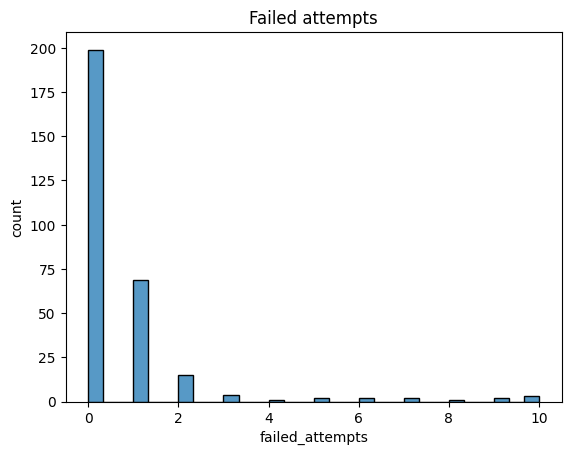

In [44]:
# Draw the histogram of failed_attempts.
# Write your code here
sns.histplot(log["failed_attempts"], bins=30)
plt.title("Failed attempts"); plt.xlabel("failed_attempts"); plt.ylabel("count"); plt.show()

In [45]:
# Auto-graded cell - Skip it...

In [46]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [ ]:
# Write your code here
answer_q2 = "B"

In [ ]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
log["night"] = (log["hour"] < 6).astype(int)   # skip this line if the night column already exists in your notebook
log.groupby("night")["failed_attempts"].mean().plot.bar(title="Mean failed attempts per night value")
plt.ylabel("mean failed_attempts"); plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
 X[:, 2] returns the third column (index 2) of X, that is the value of the third feature for all 300 samples, as a 1-dimensional array of shape (300,).

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [ ]:
# Write your code here

pd.isna(log).sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
sns.boxplot(data=log, x="country", y="failed_attempts")
plt.title("Failed attempts per country"); plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
We scale features so that they are all on the same scale and no feature  dominates the others .

Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
# Write your code here
log.to_csv("logins_clean.csv", index=False)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
# Write your code here
# Load the cleaned table
df = pd.read_csv("logins_clean.csv")

# Build the matrix X
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy()

# Scale it as in Cell 1.5: subtract the mean, divide by the std, per column
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print(X_scaled.shape)   # (300, 4)

In [ ]:
import numpy as np
import pandas as pd
